# 01. Data preparation (v2)
Patient-level splits, a validation set, and preprocessing fitted on training data only.
Run the cells in order. Everything is saved to `privacy-audit/v2/data/`.

In [ ]:
import os, sys, json, gc, time, warnings, subprocess
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
ROOT = os.environ.get("PA_ROOT", "/content/drive/MyDrive/privacy-audit/")
sys.path.insert(0, ROOT)          # pa_lib.py must sit in the privacy-audit folder on Drive
def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
from pa_lib import *
make_dirs()
print(versions())


Mounted at /content/drive
{'python': '3.13.18', 'numpy': '2.1.3', 'pandas': '2.2.3', 'torch': '2.11.0+cpu', 'opacus': None, 'art': None, 'sklearn': '1.6.1'}


In [ ]:
SEED = 42
N_PATIENTS = 15000
RAW = ROOT + "raw/diabetic_data.csv"
if not os.path.exists(RAW):
    import io, urllib.request, zipfile
    os.makedirs(ROOT + "raw", exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
    try:
        zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extract("diabetic_data.csv", ROOT + "raw")
    except Exception as e:
        raise RuntimeError(f"Could not download the dataset ({e}). Put diabetic_data.csv in {ROOT}raw/ and run this cell again.")

df = pd.read_csv(RAW)
pd.DataFrame({"column": df.columns, "type": df.dtypes.astype(str).values,
              "unique values": [df[c].nunique() for c in df.columns],
              "missing (?)": [int((df[c] == "?").sum()) for c in df.columns]}).to_csv(RESULTS + "variables_table.csv", index=False)

log = [("Raw data", len(df), df["patient_nbr"].nunique())]
def step(name):
    log.append((name, len(df), df["patient_nbr"].nunique()))

df = df.replace("?", np.nan)
df = df.drop(columns=["weight", "payer_code", "medical_specialty", "encounter_id"])
const = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=const)
print("constant columns dropped:", const)
df["max_glu_serum"] = df["max_glu_serum"].fillna("None")      # missing here means "test not done"
df["A1Cresult"] = df["A1Cresult"].fillna("None")

df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]; step("Removed patients who died or went to hospice")
df = df.dropna(subset=["race", "diag_1", "diag_2", "diag_3"]); step("Removed rows with missing race or diagnosis")
df = df[df["gender"] != "Unknown/Invalid"]; step("Removed unknown gender")
df["outcome"] = (df["readmitted"] == "<30").astype(int)       # 1 = readmitted within 30 days
df = df.drop(columns="readmitted")

def group_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("E") or code.startswith("V"):
        return "Other"
    try:
        c = float(code)
    except ValueError:
        return "Other"
    if 390 <= c <= 459 or c == 785: return "Circulatory"
    if 460 <= c <= 519 or c == 786: return "Respiratory"
    if 520 <= c <= 579 or c == 787: return "Digestive"
    if 250 <= c < 251: return "Diabetes"
    if 800 <= c <= 999: return "Injury"
    if 710 <= c <= 739: return "Musculoskeletal"
    if 580 <= c <= 629 or c == 788: return "Genitourinary"
    if 140 <= c <= 239: return "Neoplasms"
    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].apply(group_diagnosis)
id_cols = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
df[id_cols] = df[id_cols].astype(str)                          # these are category codes, not quantities

patients_all = np.sort(df["patient_nbr"].unique())
keep = np.random.RandomState(SEED).choice(patients_all, min(N_PATIENTS, len(patients_all)), replace=False)
df = df[df["patient_nbr"].isin(keep)].reset_index(drop=True); step(f"Random sample of {len(keep)} patients")

cleaning_log = pd.DataFrame(log, columns=["step", "rows", "patients"])
print(cleaning_log.to_string(index=False))
print("duplicate rows:", int(df.duplicated().sum()), "| readmitted share:", round(df["outcome"].mean(), 3))


constant columns dropped: ['examide', 'citoglipton']
                                        step   rows  patients
                                    Raw data 101766     71518
Removed patients who died or went to hospice  99343     69990
 Removed rows with missing race or diagnosis  95673     67129
                      Removed unknown gender  95672     67128
             Random sample of 15000 patients  21305     15000
duplicate rows: 0 | readmitted share: 0.114


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. split PATIENTS (never single visits). Stratified on "was this patient ever readmitted".
pat = df.groupby("patient_nbr")["outcome"].max()
P, ever = pat.index.values, pat.values
tgt_p, sh_p, tgt_e, sh_e = train_test_split(P, ever, test_size=0.5, random_state=SEED, stratify=ever)
rest_p, te_p, rest_e, _ = train_test_split(tgt_p, tgt_e, test_size=0.30, random_state=SEED, stratify=tgt_e)
tr_p, va_p = train_test_split(rest_p, test_size=0.15 / 0.70, random_state=SEED, stratify=rest_e)
shtr_p, shte_p = train_test_split(sh_p, test_size=0.30, random_state=SEED, stratify=sh_e)
groups = {"target_train": tr_p, "target_val": va_p, "target_test": te_p, "shadow_train": shtr_p, "shadow_test": shte_p}
raw_split = {k: df[df["patient_nbr"].isin(v)].reset_index(drop=True) for k, v in groups.items()}

# 2. one-hot encoding: the category list comes from target_train only
tr = raw_split["target_train"]
cat_cols = [c for c in tr.columns if not pd.api.types.is_numeric_dtype(tr[c]) and not pd.api.types.is_bool_dtype(tr[c])]
print("categorical columns:", len(cat_cols))
cats = {c: sorted(tr[c].unique()) for c in cat_cols}
def encode(d):
    d = d.copy()
    for c in cat_cols:
        d[c] = pd.Categorical(d[c], categories=cats[c])         # unseen values become all zeros
    return pd.get_dummies(d, columns=cat_cols, drop_first=True)
enc = {k: encode(d) for k, d in raw_split.items()}
cols = list(enc["target_train"].columns)
assert all(list(d.columns) == cols for d in enc.values())

# 3. scaling: fitted on target_train only
num_cols = [c for c in cols if c not in ("outcome", "patient_nbr") and enc["target_train"][c].dtype.kind in "if"]
scaler = StandardScaler().fit(enc["target_train"][num_cols].astype(float))
for d in enc.values():
    d[num_cols] = scaler.transform(d[num_cols].astype(float))
print("scaled columns:", len(num_cols), "| total features:", len(cols) - 2)


categorical columns: 34
scaled columns: 8 | total features: 118


In [ ]:
# 4. save everything
manifest, summary_rows = [], []
for name, d in enc.items():
    pd.DataFrame({"patient_nbr": d["patient_nbr"]}).to_csv(DATA + name + "_patients.csv", index=False)   # row-to-patient link
    d.drop(columns=["patient_nbr"]).to_csv(DATA + name + ".csv", index=False)
    manifest += [(p, name) for p in d["patient_nbr"].unique()]
    summary_rows.append({"split": name, "rows": len(d), "patients": int(d["patient_nbr"].nunique()),
                         "readmitted_rows": int(d["outcome"].sum()), "readmitted_share": round(float(d["outcome"].mean()), 4)})
pd.DataFrame(manifest, columns=["patient_nbr", "split"]).to_csv(DATA + "split_manifest.csv", index=False)
features = [c for c in cols if c not in ("patient_nbr", "outcome")]
json.dump({"seed": SEED, "n_patients_sampled": int(len(keep)), "features": features, "scaled_columns": num_cols,
           "categories": cats, "scaler_fit_on": "target_train", "scaler_mean": scaler.mean_.tolist(),
           "scaler_scale": scaler.scale_.tolist(), "library_versions": versions()}, open(DATA + "preprocessing.json", "w"), indent=2)
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS + "split_summary.csv", index=False)
cleaning_log.to_csv(RESULTS + "cleaning_log.csv", index=False)
print(summary.to_string(index=False))
print("rows in splits:", int(summary["rows"].sum()), "| rows after cleaning:", len(df))


       split  rows  patients  readmitted_rows  readmitted_share
target_train  5969      4125              669            0.1121
  target_val  1601      1125              190            0.1187
 target_test  3147      2250              348            0.1106
shadow_train  7454      5250              865            0.1160
 shadow_test  3134      2250              363            0.1158
rows in splits: 21305 | rows after cleaning: 21305


In [ ]:
# 5. verification: reload the saved files and check everything
names = list(groups)
chk = {n: pd.read_csv(DATA + n + ".csv") for n in names}
pid = {n: pd.read_csv(DATA + n + "_patients.csv")["patient_nbr"] for n in names}
cols0 = list(chk[names[0]].columns)
for n in names:
    assert list(chk[n].columns) == cols0, f"{n}: column order differs"
    assert not chk[n].isna().any().any(), f"{n}: missing values"
    assert chk[n].select_dtypes(exclude=["number", "bool"]).shape[1] == 0, f"{n}: text columns left"
    assert len(chk[n]) == len(pid[n]), f"{n}: patient file does not match"
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        shared = set(pid[names[i]]) & set(pid[names[j]])
        assert not shared, f"patients shared between {names[i]} and {names[j]}: {len(shared)}"
tr_num = chk["target_train"][num_cols]
assert abs(tr_num.mean()).max() < 1e-6, "training columns are not centred"
print("ALL CHECKS PASSED: no patient appears in two splits, columns match, no missing values, scaler fitted on training only.")


ALL CHECKS PASSED: no patient appears in two splits, columns match, no missing values, scaler fitted on training only.


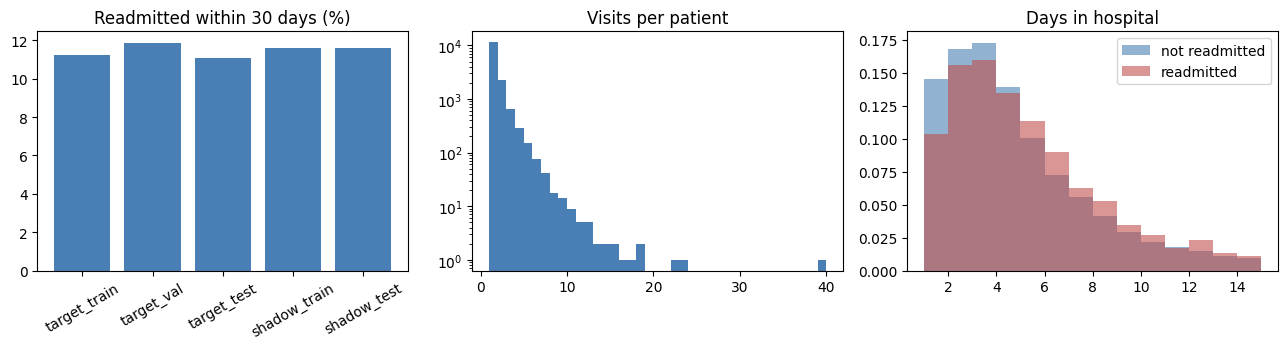

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(summary["split"], summary["readmitted_share"] * 100, color="#4a7fb5"); ax[0].set_title("Readmitted within 30 days (%)"); ax[0].tick_params(axis="x", rotation=30)
vpp = df.groupby("patient_nbr").size()
ax[1].hist(vpp, bins=range(1, int(vpp.max()) + 2), color="#4a7fb5"); ax[1].set_title("Visits per patient"); ax[1].set_yscale("log")
for v, c in ((0, "#4a7fb5"), (1, "#c0504d")):
    ax[2].hist(df.loc[df["outcome"] == v, "time_in_hospital"], bins=range(1, 16), alpha=.6, color=c, density=True, label=["not readmitted", "readmitted"][v])
ax[2].set_title("Days in hospital"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIGS + "eda_overview.png", dpi=150); plt.show()
